<a href="https://colab.research.google.com/github/marcelcerri/Python_biocientistas_unesp/blob/main/Aula_10_Drug_Delivery.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 💊 Aula Prática: Simulação de Drug Delivery Transdérmico

Bem-vindos a mais uma aula de Python aplicado às Ciências Farmacêuticas! Hoje vamos unir a **Físico-Química** com a **Programação** para simular a liberação de um fármaco a partir de um adesivo transdérmico (*patch*).

## 1. O Contexto Farmacêutico

A via transdérmica é uma alternativa muito vantajosa em relação à administração oral tradicional. Ela permite uma liberação constante do fármaco na corrente sanguínea, melhorando a adesão do paciente e, principalmente, **evitando o metabolismo de primeira passagem no fígado**.

No entanto, para que o fármaco chegue ao sangue, ele precisa primeiro vencer a principal barreira do nosso corpo: o **estrato córneo** (a camada mais externa da pele). O transporte de moléculas através dessa barreira ocorre por **difusão passiva**.

## 2. A Matemática da Difusão (Primeira Lei de Fick)

A difusão passiva em estado estacionário (quando o fluxo se torna constante) é matematicamente descrita pela **Primeira Lei de Fick**. O fluxo ($J$), que representa a massa de fármaco que atravessa uma determinada área da pele por unidade de tempo, é dado pela equação:

$$J = \frac{D \cdot K \cdot \Delta C}{h}$$

Onde:

* $J$ = Fluxo transdérmico do fármaco (ex: $mg / cm^2 \cdot h$)
* $D$ = Coeficiente de difusão do fármaco na pele (o quão rápido a molécula se move no meio)
* $K$ = Coeficiente de partição (a afinidade do fármaco pela pele em relação ao adesivo)
* $\Delta C$ = Gradiente de concentração (diferença de concentração entre o adesivo e o interior da pele)
* $h$ = Espessura da barreira (o estrato córneo)

Se conhecemos o fluxo ($J$), podemos calcular a **quantidade cumulativa total ($Q$)** de fármaco que permeou a pele após um determinado tempo ($t$), considerando a área de aplicação do adesivo ($A$):

$$Q = J \cdot A \cdot t$$

## 3. O Objetivo da Simulação em Python

Ao longo do desenvolvimento de uma nova formulação, o farmacêutico cientista precisa testar diversos fármacos com diferentes coeficientes de partição ($K$) e difusão ($D$). Fazer isso manualmente no papel ou no Excel pode ser trabalhoso.

Nesta aula, usaremos o Python para:

1. Criar uma **função automatizada** que resolva a Lei de Fick.
2. Utilizar o **NumPy** para simular o tempo contínuo de aplicação (ex: de 0 a $24$ horas).
3. Utilizar o **Pandas** para organizar nossos dados experimentais teóricos.
4. Construir gráficos comparativos de alta qualidade com o **Matplotlib**.

Vamos ao código! 🚀

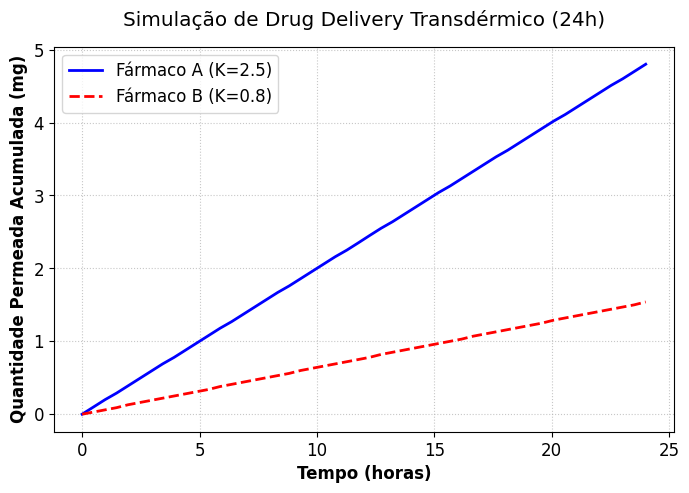

In [4]:
# -*- coding: utf-8 -*-
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Função para a Primeira Lei de Fick
def calcular_fluxo(D, K, delta_C, h):
    """
    Calcula o fluxo transdérmico (J) em mg/(cm2*h).
    """
    return (D * K * delta_C) / h

# 2. Parâmetros Físico-Químicos (Dados fictícios)
espessura_pele = 0.0015  # h em cm (estrato córneo)
area_adesivo = 10.0      # A em cm2

# Fármaco A (Alta partição)
D_A = 1.2e-6             # Coeficiente de difusão (cm2/h)
K_A = 2.5                # Coeficiente de partição
delta_C_A = 10.0         # mg/cm3

# Fármaco B (Baixa partição)
D_B = 1.2e-6
K_B = 0.8
delta_C_B = 10.0

# 3. Cálculos do Fluxo e Quantidade Cumulativa
fluxo_A = calcular_fluxo(D_A, K_A, delta_C_A, espessura_pele)
fluxo_B = calcular_fluxo(D_B, K_B, delta_C_B, espessura_pele)

# Gerando vetor de tempo de 0 a 24 horas (50 pontos)
tempo = np.linspace(0, 24, 50)

# Q = J * A * t
Q_A = fluxo_A * area_adesivo * tempo
Q_B = fluxo_B * area_adesivo * tempo

# 4. Estruturando os Resultados com Pandas
df_liberacao = pd.DataFrame({
    'Tempo (h)': np.round(tempo, 2),
    'Q_Farmaco_A (mg)': np.round(Q_A, 2),
    'Q_Farmaco_B (mg)': np.round(Q_B, 2)
})


# 5. Visualização Gráfica
plt.rc('font', size=12)
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(df_liberacao['Tempo (h)'], df_liberacao['Q_Farmaco_A (mg)'],
        label=f'Fármaco A (K={K_A})', color='blue', linewidth=2)
ax.plot(df_liberacao['Tempo (h)'], df_liberacao['Q_Farmaco_B (mg)'],
        label=f'Fármaco B (K={K_B})', color='red', linewidth=2, linestyle='--')

ax.set_title("Simulação de Drug Delivery Transdérmico (24h)", pad=15)
ax.set_xlabel('Tempo (horas)', weight='bold')
ax.set_ylabel('Quantidade Permeada Acumulada (mg)', weight='bold')
ax.grid(True, linestyle=':', alpha=0.7)
ax.legend()

plt.savefig('Perfil_Permeacao.png', dpi=300, bbox_inches='tight')
plt.show()

# Opcional: Exportar os dados gerados
# df_liberacao.to_excel('dados_permeacao.xlsx', index=False)

📈 Aula Prática: Farmacocinética e Equações Diferenciais

Na primeira etapa da nossa aula, calculamos a quantidade total de fármaco que atravessa a pele. No entanto, o corpo humano é um sistema dinâmico: assim que o fármaco entra na corrente sanguínea, nossos órgãos (como fígado e rins) já começam a trabalhar para eliminá-lo.

Para entender como a concentração do medicamento varia no corpo ao longo do tempo, precisamos da **Farmacocinética** aliada ao poder das **Equações Diferenciais Ordinárias (EDOs)**.

## 1. O Modelo de Um Compartimento com Absorção

Vamos simular o nosso adesivo transdérmico (ou um comprimido oral) usando um **modelo farmacocinético compartimental**. Imaginaremos nosso sistema dividido em dois "tanques" ou compartimentos:

1. **O Local de Absorção (Adesivo):** Onde o fármaco está inicialmente depositado e de onde ele sai.
2. **O Compartimento Central (Sangue/Corpo):** Onde o fármaco entra e de onde ele é eliminado.

A dinâmica de transferência entre esses compartimentos depende de duas constantes cinéticas (geralmente de primeira ordem):

* $k_a$: Constante de taxa de absorção (a rapidez com que o fármaco vai do adesivo para o sangue).
* $k_e$: Constante de taxa de eliminação (a rapidez com que o corpo limpa o fármaco do sangue).

## 2. O Sistema de Equações Diferenciais (EDOs)

Como as quantidades mudam simultaneamente, descrevemos o processo pelas seguintes taxas de variação em relação ao tempo ($dt$):

**1. Variação da massa no adesivo ($M_p$):**
O fármaco apenas *sai* do adesivo. Portanto, a taxa é negativa.
$$ \frac{dM_p}{dt} = -k_a \cdot M_p $$

**2. Variação da massa no sangue ($M_b$):**
O fármaco *entra* vindo do adesivo (termo positivo) e *sai* devido à eliminação (termo negativo).
$$ \frac{dM_b}{dt} = k_a \cdot M_p - k_e \cdot M_b $$

Onde:

* $M_p$ = Massa (ou concentração) do fármaco no adesivo (*patch*).
* $M_b$ = Massa (ou concentração) do fármaco no sangue (*blood*).

## 3. Parâmetros Críticos: $C_{max}$ e $T_{max}$

Na indústria farmacêutica, ao analisar o gráfico gerado por essas equações, buscamos identificar dois parâmetros fundamentais para a eficácia e segurança do tratamento:

* **$C_{max}$ (Pico Plasmático):** A concentração ou quantidade máxima que o fármaco atinge na corrente sanguínea.
* **$T_{max}$ (Tempo Máximo):** O tempo exato necessário para que esse pico seja atingido.

## 4. O Papel do Python (SciPy)

Resolver esses sistemas de EDOs à mão requer cálculo avançado (como transformadas de Laplace). Mas, usando a programação científica, isso se torna instantâneo!

Hoje utilizaremos a poderosa função `odeint` da biblioteca **SciPy** (`scipy.integrate`). Ela fará a integração numérica do nosso sistema, bastando que a gente defina as equações, as condições iniciais (quanto fármaco temos no tempo zero) e o tempo de simulação.

Vamos programar nosso modelo dinâmico! 💻

Pico Plasmático (Cmax): 62.99 mg
Tempo para o Pico (Tmax): 9.17 horas


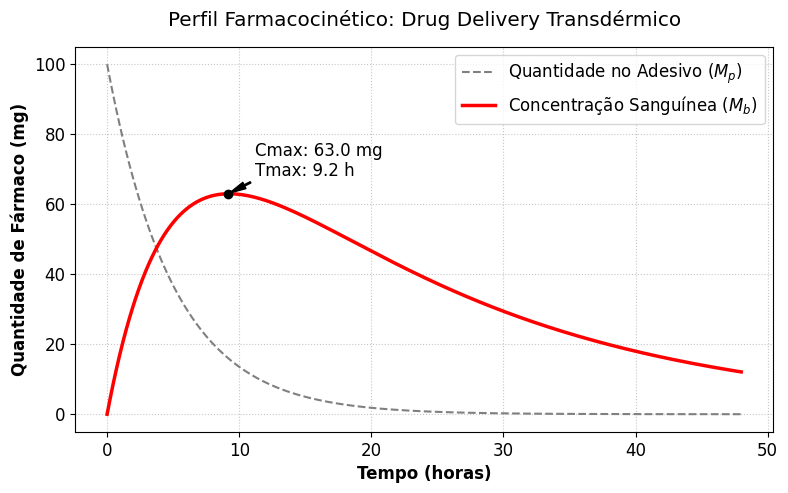

In [2]:
# -*- coding: utf-8 -*-
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

# 1. Definição do Sistema de Equações Diferenciais
def modelo_farmacocinetico(y, t, ka, ke):
    """
    Sistema de EDOs para um modelo de 1 compartimento com absorção.
    y[0] = Mp (Massa no adesivo)
    y[1] = Mb (Massa no sangue)
    """
    Mp, Mb = y

    # EDO do Adesivo: o fármaco apenas sai
    dMp_dt = -ka * Mp

    # EDO do Sangue: o fármaco entra vindo do adesivo e sai pela eliminação
    dMb_dt = (ka * Mp) - (ke * Mb)

    return [dMp_dt, dMb_dt]

# 2. Parâmetros da Simulação
ka = 0.2  # Constante de absorção (h^-1)
ke = 0.05 # Constante de eliminação (h^-1)

# Condições iniciais: 100 mg no adesivo, 0 mg no sangue no tempo t=0
y0 = [100.0, 0.0]

# Vetor de tempo: simulação de 0 a 48 horas (resolução de 200 pontos)
t = np.linspace(0, 48, 200)

# 3. Resolução do Sistema de EDOs
# O odeint resolve as equações e devolve uma matriz com os resultados de Mp e Mb
resultados = odeint(modelo_farmacocinetico, y0, t, args=(ka, ke))

# Separando os resultados para facilitar a plotagem
Mp_simulado = resultados[:, 0]
Mb_simulado = resultados[:, 1]

# Identificando o Pico Plasmático (Cmax) e o Tempo Máximo (Tmax)
cmax_idx = np.argmax(Mb_simulado)
tmax = t[cmax_idx]
cmax = Mb_simulado[cmax_idx]
print(f"Pico Plasmático (Cmax): {cmax:.2f} mg")
print(f"Tempo para o Pico (Tmax): {tmax:.2f} horas")

# 4. Visualização Gráfica
plt.rc('font', size=12)
fig, ax = plt.subplots(figsize=(9, 5))

# Plotando o esgotamento do adesivo e a curva plasmática
ax.plot(t, Mp_simulado, label='Quantidade no Adesivo ($M_p$)', color='gray', linestyle='--')
ax.plot(t, Mb_simulado, label='Concentração Sanguínea ($M_b$)', color='red', linewidth=2.5)

# Marcando o Cmax no gráfico
ax.plot(tmax, cmax, 'ko')
ax.annotate(f'Cmax: {cmax:.1f} mg\nTmax: {tmax:.1f} h',
            xy=(tmax, cmax), xytext=(tmax + 2, cmax + 5),
            arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=5))

ax.set_title("Perfil Farmacocinético: Drug Delivery Transdérmico", pad=15)
ax.set_xlabel('Tempo (horas)', weight='bold')
ax.set_ylabel('Quantidade de Fármaco (mg)', weight='bold')
ax.grid(True, linestyle=':', alpha=0.7)
ax.legend()

plt.savefig('Perfil_Farmacocinetico_EDO.png', dpi=300, bbox_inches='tight')
plt.show()

📝 Exercícios de Aplicação: Modelagem de Drug Delivery

Nesta etapa, você colocará à prova os códigos que desenvolvemos na aula. O seu objetivo não é reescrever os programas do zero, mas sim atuar como um Cientista de Formulação: você deverá alterar as **variáveis de entrada** no código e analisar criticamente os resultados gráficos gerados.

---

## Parte 1: Difusão Transdérmica (Primeira Lei de Fick)

**Exercício 1: O Impacto da Lipofilicidade**
O coeficiente de partição ($K$) indica o quão bem um fármaco prefere o ambiente rico em lipídios da pele em comparação ao adesivo. Você está avaliando dois análogos do mesmo fármaco para um novo adesivo de 15 cm² de área, aplicado por 24 horas.

* **Fármaco X (Alta Lipofilicidade):** $K = 3.0$
* **Fármaco Y (Baixa Lipofilicidade):** $K = 0.5$

*Dados fixos para ambos:* $D = 1.5 \times 10^{-6} \text{ cm}^2/\text{h}$, $\Delta C = 5.0 \text{ mg/cm}^3$, espessura ($h$) = $0.002 \text{ cm}$.
**Sua Tarefa:** Insira esses dados no código da Primeira Lei de Fick. Qual dos fármacos apresenta a maior quantidade cumulativa permeada ao final das 24 horas?

**Exercício 2: Escalonamento para Uso Pediátrico**
Você formulou um adesivo transdérmico para uso adulto que permeia uma quantidade ideal do fármaco em 12 horas. Agora, a equipe médica solicitou uma versão pediátrica que entregue exatamente a metade da dose no mesmo período.

* **Adesivo Adulto:** Área = 20 cm², $\Delta C = 10.0 \text{ mg/cm}^3$
* **Adesivo Pediátrico:** Área = 10 cm², $\Delta C = 10.0 \text{ mg/cm}^3$

*Dados fixos para ambos:* $D = 2.0 \times 10^{-6} \text{ cm}^2/\text{h}$, $K = 1.5$, espessura ($h$) = $0.0015 \text{ cm}$, Tempo = 12 horas.
**Sua Tarefa:** Modifique o tempo de simulação no código para 12 horas (ao invés de 24h) e rode a simulação para as duas áreas de adesivo. A estratégia de cortar a área do adesivo pela metade funciona matematicamente para reduzir a dose pela metade?

---

## Parte 2: Farmacocinética Dinâmica (Equações Diferenciais)

**Exercício 3: Promotores de Permeação e o $T_{max}$**
Para acelerar o efeito de um analgésico transdérmico, a equipe de P&D adicionou um promotor de permeação químico na formulação, o que aumentou a taxa de absorção ($k_a$). O tempo de simulação será de 72 horas para uma dose inicial de 50 mg no adesivo.

* **Formulação Padrão:** $k_a = 0.10 \text{ h}^{-1}$
* **Formulação com Promotor:** $k_a = 0.30 \text{ h}^{-1}$

*Dado fixo:* $k_e = 0.04 \text{ h}^{-1}$.
**Sua Tarefa:** Rode a EDO para as duas formulações. O que acontece com o Pico Plasmático ($C_{max}$) e o Tempo Máximo ($T_{max}$) quando aumentamos o $k_a$? O promotor atingiu o objetivo de acelerar o efeito?

**Exercício 4: Segurança em Pacientes com Insuficiência Renal**
O fármaco que estamos modelando é excretado exclusivamente pelos rins. Uma falha renal afeta a taxa de eliminação ($k_e$), tornando a limpeza do sangue mais lenta. Avalie o risco de superdosagem comparando um paciente saudável com um paciente com insuficiência renal durante uma simulação de 48 horas (Dose = 100 mg).

* **Paciente Saudável:** $k_e = 0.10 \text{ h}^{-1}$
* **Paciente Insuficiência Renal:** $k_e = 0.02 \text{ h}^{-1}$

*Dado fixo:* $k_a = 0.15 \text{ h}^{-1}$.
**Sua Tarefa:** Rode o sistema para ambos os casos. Qual é o $C_{max}$ atingido pelo paciente com insuficiência renal? Em termos clínicos, qual é o perigo visível no formato da curva desse paciente?